KNN algoritam sa ukljucenim svakim mogucim featurom

For K: 1: Test set accuracy: 0.9666666666666667
For K: 2: Test set accuracy: 0.9
For K: 3: Test set accuracy: 0.9666666666666667
For K: 4: Test set accuracy: 0.9
For K: 5: Test set accuracy: 0.9
For K: 6: Test set accuracy: 0.9333333333333333
For K: 7: Test set accuracy: 0.9333333333333333
For K: 8: Test set accuracy: 0.9666666666666667
For K: 9: Test set accuracy: 0.9666666666666667
For K: 10: Test set accuracy: 0.9666666666666667
For K: 11: Test set accuracy: 0.9666666666666667
For K: 12: Test set accuracy: 0.9666666666666667
For K: 13: Test set accuracy: 0.9333333333333333
For K: 14: Test set accuracy: 0.9666666666666667
For K: 15: Test set accuracy: 0.9333333333333333


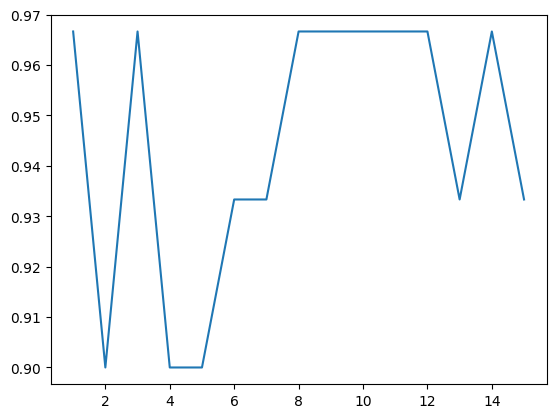

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt


class KNN:

  def __init__(self, nb_features, nb_classes, data):
    self.nb_features = nb_features
    self.nb_classes = nb_classes
    self.X = tf.convert_to_tensor(data['x'], dtype=tf.float32)
    self.Y = tf.convert_to_tensor(data['y'], dtype=tf.int32)

    #predict fja
  def predict(self,query_data, k):

      nb_queries = query_data['x'].shape[0]

      matches = 0

      for i in range(nb_queries):

        #Racunamo euklidsku distancu
        dists = tf.sqrt(tf.reduce_sum(tf.square(tf.subtract(self.X, query_data['x'][i])), axis=1))
        #uzimamo top k sa najmanjom
        _, idxs = tf.nn.top_k(-dists, k)

        #skuplja top k distanci i njihove klase
        classes = tf.gather(self.Y, idxs)
        dists = tf.gather(dists, idxs)

        w = tf.fill([k], 1/k)
        w_col = tf.reshape(w, (k, 1))
        classes_one_hot = tf.one_hot(classes, self.nb_classes)
        scores = tf.reduce_sum(w_col * classes_one_hot, axis=0)

        hyp = tf.argmax(scores)

        if query_data['y'] is not None:
          actual = query_data['y'][i]
          match = (hyp == actual)
          if match:
            matches += 1
      if query_data['y'] is not None:
        accuracy = matches / nb_queries
        print(f'For K: {k}: Test set accuracy: {accuracy}')

      return accuracy


#prva 2 featura
features = np.loadtxt("iris.csv", delimiter=',', usecols = (0,1,2,3), dtype='float32', skiprows=1)
#naziv cveta
labels_1 = np.loadtxt("iris.csv", delimiter=',', usecols = (4), dtype=str, skiprows=1)

#normalizacija featura:
features = (features - np.mean(features, axis=0)) / np.std(features, axis=0)

#shuffle zbog pravilnosti:
nb_samples = len(features)
indices = np.random.permutation(nb_samples)
features = features[indices]
labels_1 = labels_1[indices]

#dekodiramo string u brojeve radi lakseg handlovanja
label_names, labels = np.unique(labels_1, return_inverse=True)

#delimo podatke na trening i test - 80% na trening
split_num = int(nb_samples*0.8)
train_x = features[:split_num]
test_x = features[split_num:]

train_y = labels[:split_num]
test_y = labels[split_num:]

#pokretanje K-NN algoritma
nb_features = train_x.shape[1]
nb_classes = len(label_names)
train_data = {'x': train_x, 'y': train_y}
knn = KNN(nb_features, nb_classes, train_data)
results = []

for k in range (1,16):
  results.append(knn.predict({'x': test_x, 'y': test_y}, k))

#plot
plt.plot(np.arange(1,16), results)
plt.show()


#Prilikom pokretanja koda nekoliko puta sa razlicitim permutacijama podataka, knn algoritam
#koji koristi sve dostupne feature iz data seta daje konstantno daleko bolje rezultate
#od kNN algoritma koji koristi samo 2 featura